# 04 · Model-ready datasets & train/test split
We prepare **three modelling tables**, one per question the web app answers, and split each in the way that matches how the model will be used.
A random row split on time-series data leaks the future into training, so each table gets its own strategy:

| Dataset | Grain | App question | Split strategy |
|---|---|---|---|
| **Monthly** | product × month | *"What will this product do next month?"* (units, demand, price, revenue, profit, margin, ROI) | **Temporal holdout**: train ≤ Sep 2025, test = Oct 2025 → Sep 2026 (a full year incl. BFCM and Prime Day) |
| **Yearly** | product × year | *"How will it do this year?"* | **Temporal**: train ≤ 2024, test = 2025 (2026 is a partial year, kept separately for scoring) |
| **Product launch** | product | *"If I launch / invest in this, what are the first 12 months and when do I break even?"* | **Product-level 80/20 split stratified by category** (no product in both sets) |

Leakage rules applied:
1. Features for month *t* use only information available **before** *t* (lags, rolling stats, cumulative to *t−1*), plus **plannable** inputs: price, promo depth, calendar.
2. Stock-outs, refunds, fees, demand share in the target month are **outcomes**, not features.
3. Encoders and scalers are **not** fitted here. They're fitted on train inside the modelling pipeline. We only apply deterministic transforms (logs, fixed one-hot vocabularies).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mtick, seaborn as sns
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

# One consistent, colour-blind-checked palette for every chart (fixed order: colour follows the entity)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ = sns.blend_palette(["#cde2fb", "#2a78d6", "#0d366b"], as_cmap=True)
DIV = sns.blend_palette(["#2a78d6", "#f0efec", "#e34948"], as_cmap=True)
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.prop_cycle": plt.cycler(color=SERIES),
    "lines.linewidth": 2, "figure.dpi": 110, "font.size": 10, "legend.frameon": False,
})
usd = mtick.StrMethodFormatter("${x:,.0f}")
import matplotlib.dates as mdates
def fmt_dates(ax):
    loc = mdates.AutoDateLocator(minticks=3, maxticks=8); ax.xaxis.set_major_locator(loc); ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
def savefig(fig, name): fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
import json, re
PROC = ROOT / "data/processed"; FINAL = ROOT / "data/final"; FINAL.mkdir(parents=True, exist_ok=True)
products = pd.read_csv(PROC / "product_features.csv", parse_dates=["launch_date"])
monthly  = pd.read_csv(PROC / "monthly_panel.csv", parse_dates=["month"])
yearly   = pd.read_csv(PROC / "yearly_panel.csv")
summary  = pd.read_csv(PROC / "product_summary.csv", parse_dates=["launch_date"])
print(products.shape, monthly.shape, yearly.shape, summary.shape)

(1351, 47) (83316, 42) (7915, 22) (1351, 67)


## 1. Static product features (shared by all three datasets)
- Group long-tail categories (< 10 products) into **"Other"**.
- Log-transform skewed money and count fields.
- Drop columns that are redundant (EDA §4) or are outcomes of the simulation (`lifetime_units`, `break_even_*`, `initial_inventory_cost`, which depends on realised sales).
- Fixed-vocabulary one-hot for low-cardinality categoricals. `brand` stays raw for target encoding inside the pipeline.

In [2]:
big = products.us_category.value_counts().loc[lambda s: s >= 10].index
products["category_group"] = np.where(products.us_category.isin(big), products.us_category, "Other")
for c in ["price_usd", "list_price_usd", "rating_count", "ship_weight_lb", "landed_cost_unit", "fba_fee_unit", "brand_listing_count", "launch_fixed_cost"]:
    products[f"log_{c}"] = np.log1p(products[c])
products["deep_discount_listing"] = (products.orig_discount_pct > 60).astype(int)
products["fee_share_of_price"] = ((products.fba_fee_unit + products.referral_fee_unit) / products.price_usd).round(4)
products["cost_share_of_price"] = (products.landed_cost_unit / products.price_usd).round(4)

ONEHOT = {"category_group": sorted(products.category_group.unique()), "size_tier": sorted(products.size_tier.unique()),
          "price_tier": ["<$10", "$10-25", "$25-50", "$50-100", "$100-250", "$250+"],
          "rating_band": ["<3.5", "3.5-3.8", "3.8-4.0", "4.0-4.2", "4.2-4.4", "4.4+"]}
def onehot(d):
    out = d.copy()
    for col, vocab in ONEHOT.items():
        for v in vocab:
            out[f"{col}__{re.sub(r'[^0-9a-zA-Z]+', '_', v).strip('_')}"] = (out[col] == v).astype(int)
    return out
P = onehot(products)
OH_COLS = [c for c in P.columns if "__" in c]

STATIC_FEATURES = ["log_price_usd", "log_list_price_usd", "discount_pct", "deep_discount_listing", "rating", "review_sentiment",
                   "listing_quality_score", "log_brand_listing_count", "is_bundle", "cat_depth", "name_len", "n_bullets",
                   "log_ship_weight_lb", "cubic_ft", "log_fba_fee_unit", "log_landed_cost_unit", "referral_rate", "return_rate",
                   "tacos_rate", "price_elasticity", "fee_share_of_price", "cost_share_of_price", "unit_margin_pct",
                   "launch_month", "log_launch_fixed_cost"] + OH_COLS
ID_COLS = ["product_id", "product_name", "brand", "us_category", "category_group", "cat_leaf"]
print(len(STATIC_FEATURES), "static features")

52 static features


## 2. Monthly dataset: lag and rolling features
Lags are computed over each product's **full history from launch**, then the modelling window is restricted to **Jan 2021 → Sep 2026**
(older months still feed the lags). `month_of_year` is encoded cyclically (sin/cos) so December sits next to January.

In [3]:
M = monthly.sort_values(["product_id", "month"]).copy()
grp = M.groupby("product_id")
for col in ["units_sold", "demand_units", "avg_price", "net_profit", "gross_revenue", "profit_margin_pct", "demand_share_pct"]:
    for L in (1, 2, 3, 12):
        if col in ("profit_margin_pct", "demand_share_pct") and L in (2, 3):  # keep the feature set compact
            continue
        M[f"{col}_lag{L}"] = grp[col].shift(L)
for col in ["units_sold", "demand_units", "net_profit"]:
    sh = grp[col].shift(1)
    for w in (3, 6, 12):
        M[f"{col}_roll{w}_mean"] = sh.groupby(M.product_id).transform(lambda s: s.rolling(w, min_periods=1).mean())
M["units_roll3_std"] = grp.units_sold.shift(1).groupby(M.product_id).transform(lambda s: s.rolling(3, min_periods=2).std())
M["units_trend_3v12"] = M.units_sold_roll3_mean / M.units_sold_roll12_mean.replace(0, np.nan)
M["reviews_to_date_lag1"] = grp.reviews_to_date.shift(1).fillna(0)
M["cum_units_sold_lag1"] = grp.cum_units_sold.shift(1).fillna(0)
M["cum_net_profit_lag1"] = grp.cum_net_profit.shift(1).fillna(0)
M["roi_cum_pct_lag1"] = grp.roi_cum_pct.shift(1)
M["price_vs_everyday"] = (M.avg_price / M.everyday_price).round(4)          # plannable promo intensity
M["log_avg_price"] = np.log(M.avg_price)
M["moy_sin"], M["moy_cos"] = np.sin(2 * np.pi * M.month_of_year / 12), np.cos(2 * np.pi * M.month_of_year / 12)
M["log_age_months"] = np.log1p(M.age_months)
M["is_launch_phase"] = (M.age_months < 6).astype(int)

M = M[M.month >= "2021-01-01"].merge(P[ID_COLS + STATIC_FEATURES], on="product_id", how="left")
print(M.shape)

(68299, 144)


In [4]:
MONTHLY_TARGETS = {
    "units_sold": "Units sold in month",
    "demand_units": "Unconstrained demand in units",
    "demand_share_pct": "Demand as % of tracked category demand",
    "demand_growth_mom_pct": "Demand % change vs previous month",
    "avg_price": "Average selling price (USD)",
    "gross_revenue": "Sales / revenue (USD)",
    "net_profit": "Net profit after all Amazon fees, COGS, ads (USD)",
    "profit_margin_pct": "Net profit ÷ gross revenue × 100",
    "roi_unit_pct": "Per-unit profit ÷ landed cost × 100",
    "roi_cum_pct": "Cumulative profit since launch ÷ capital invested × 100",
}
CALENDAR = ["month_of_year", "moy_sin", "moy_cos", "year", "is_prime_day", "is_prime_big_deal_days", "is_bfcm", "is_holiday_peak",
            "is_back_to_school", "macro_index"]
PLANNABLE = ["age_months", "log_age_months", "is_launch_phase", "promo_flag", "promo_depth_pct", "everyday_price", "avg_price",
             "log_avg_price", "price_vs_everyday"]
LAGS = [c for c in M.columns if re.search(r"_lag\d+$|_roll\d+_mean$|roll3_std$|trend_3v12$", c)]
MONTHLY_FEATURES = CALENDAR + PLANNABLE + LAGS + STATIC_FEATURES
# When predicting price itself, same-month price inputs must be removed
PRICE_INPUTS = ["avg_price", "log_avg_price", "price_vs_everyday", "promo_depth_pct", "promo_flag"]
print(f"{len(MONTHLY_FEATURES)} monthly features | {len(LAGS)} lag/rolling features")
leak = set(MONTHLY_FEATURES) & {"stockout_flag", "lost_demand_frac", "refunds", "net_revenue", "total_costs", "cum_net_profit", "demand_index"}
assert not leak, leak

110 monthly features | 39 lag/rolling features


### 2.1 Temporal split
Test = the **last 12 months (Oct 2025 – Sep 2026)**, so the test set contains a full seasonal cycle: Prime Big Deal Days, BFCM, holiday, Prime Day and back-to-school.
Products launched during the test window appear **only** in test, like real new launches.

In [5]:
SPLIT = pd.Timestamp("2025-10-01")
keep = ["product_id", "month"] + ID_COLS[1:] + MONTHLY_FEATURES + list(MONTHLY_TARGETS) + ["stockout_flag"]
keep = list(dict.fromkeys(keep))
m_train = M.loc[M.month < SPLIT, keep].reset_index(drop=True)
m_test  = M.loc[M.month >= SPLIT, keep].reset_index(drop=True)
print(f"train {m_train.shape}  {m_train.month.min():%Y-%m} → {m_train.month.max():%Y-%m}")
print(f"test  {m_test.shape}  {m_test.month.min():%Y-%m} → {m_test.month.max():%Y-%m}")
assert m_train.month.max() < m_test.month.min()
new_in_test = set(m_test.product_id) - set(m_train.product_id)
print("Products that exist only in test (launched after Sep 2025):", len(new_in_test))

train (52245, 127)  2021-01 → 2025-09
test  (16054, 127)  2025-10 → 2026-09
Products that exist only in test (launched after Sep 2025): 67


## 3. Yearly dataset

In [6]:
Yd = yearly.sort_values(["product_id", "year"]).copy()
yg = Yd.groupby("product_id")
for col in ["units_sold", "demand_units", "gross_revenue", "net_profit", "profit_margin_pct", "avg_price"]:
    Yd[f"{col}_prev_year"] = yg[col].shift(1)
Yd["months_active_prev_year"] = yg.months_active.shift(1)
Yd["years_since_launch"] = Yd.year - Yd.product_id.map(products.set_index("product_id").launch_year)
Yd = Yd.merge(P[ID_COLS + STATIC_FEATURES], on=["product_id", "us_category"], how="left")
YEARLY_TARGETS = ["units_sold", "demand_units", "demand_share_pct", "demand_growth_yoy_pct", "avg_price", "gross_revenue",
                  "net_profit", "profit_margin_pct", "roi_year_pct", "roi_cum_pct"]
YEARLY_FEATURES = ["year", "years_since_launch", "months_active", "promo_months", "is_partial_year"] + \
                  [c for c in Yd.columns if c.endswith("_prev_year")] + STATIC_FEATURES
ykeep = list(dict.fromkeys(["product_id", "year"] + ID_COLS[1:] + YEARLY_FEATURES + YEARLY_TARGETS))
y_train = Yd.loc[Yd.year <= 2024, ykeep].reset_index(drop=True)
y_test  = Yd.loc[Yd.year == 2025, ykeep].reset_index(drop=True)
y_score = Yd.loc[Yd.year == 2026, ykeep].reset_index(drop=True)   # partial year (Jan–Sep): for app scoring, not evaluation
print("yearly train", y_train.shape, "| test", y_test.shape, "| 2026 partial", y_score.shape)

yearly train (5244, 80) | test (1320, 80) | 2026 partial (1351, 80)


## 4. Product launch dataset (first 12 / 24 months + break-even)
**Two feature sets**, because the app has two use cases:
- **`LAUNCH_FEATURES`**: what an entrepreneur knows *before* launch (price, category, size, fees, costs, expected quality). No review counts.
- **`LISTING_FEATURES`**: evaluating an **existing listing** to invest in. Adds `log_rating_count`, a strong market-traction signal that is a legitimate input here but would leak in the launch case.

Targets are `NaN` for products too young to have a full window. Each model drops those rows per target, so we keep them rather than discard products.

In [7]:
Sx = onehot(summary.merge(products[["product_id", "category_group"] + [c for c in products.columns if c.startswith("log_")] +
                         ["deep_discount_listing", "fee_share_of_price", "cost_share_of_price"]], on="product_id", how="left"))
Sx["break_even_months_log"] = np.log1p(Sx.break_even_months)
Sx["break_even_bucket"] = pd.cut(Sx.break_even_months, [0, 3, 6, 12, 24, 1e9], labels=["0-3m", "4-6m", "7-12m", "13-24m", "24m+"]).astype(str)
Sx.loc[Sx.never_breaks_even == 1, "break_even_bucket"] = "never"
Sx.loc[Sx.break_even_months.isna() & (Sx.never_breaks_even == 0), "break_even_bucket"] = np.nan

LAUNCH_FEATURES = STATIC_FEATURES
LISTING_FEATURES = STATIC_FEATURES + ["log_rating_count"]
LAUNCH_TARGETS = ["units_sold_12m", "demand_units_12m", "avg_monthly_demand_12m", "demand_share_pct_12m", "avg_price_12m",
                  "revenue_12m", "profit_12m", "margin_pct_12m", "roi_pct_12m",
                  "units_sold_24m", "revenue_24m", "profit_24m", "margin_pct_24m", "roi_pct_24m",
                  "break_even_months", "break_even_months_log", "break_even_bucket", "never_breaks_even"]
pkeep = list(dict.fromkeys(ID_COLS + ["launch_date", "age_months_at_obs_end", "log_rating_count"] + LAUNCH_FEATURES + LAUNCH_TARGETS))

from sklearn.model_selection import train_test_split
p_train, p_test = train_test_split(Sx[pkeep], test_size=0.20, random_state=42, stratify=Sx.category_group)
p_train, p_test = p_train.reset_index(drop=True), p_test.reset_index(drop=True)
assert not set(p_train.product_id) & set(p_test.product_id)
print("product train", p_train.shape, "| test", p_test.shape)
p_train[LAUNCH_TARGETS].notna().sum().to_frame("train_rows_with_target").join(p_test[LAUNCH_TARGETS].notna().sum().rename("test_rows_with_target"))

product train (1080, 79) | test (271, 79)


,train_rows_with_target,test_rows_with_target
units_sold_12m,1038,256
demand_units_12m,1038,256
avg_monthly_demand_12m,1038,256
demand_share_pct_12m,1038,256
avg_price_12m,1038,256
revenue_12m,1038,256
profit_12m,1038,256
margin_pct_12m,1038,256
roi_pct_12m,1038,256
units_sold_24m,911,224


## 5. Split diagnostics

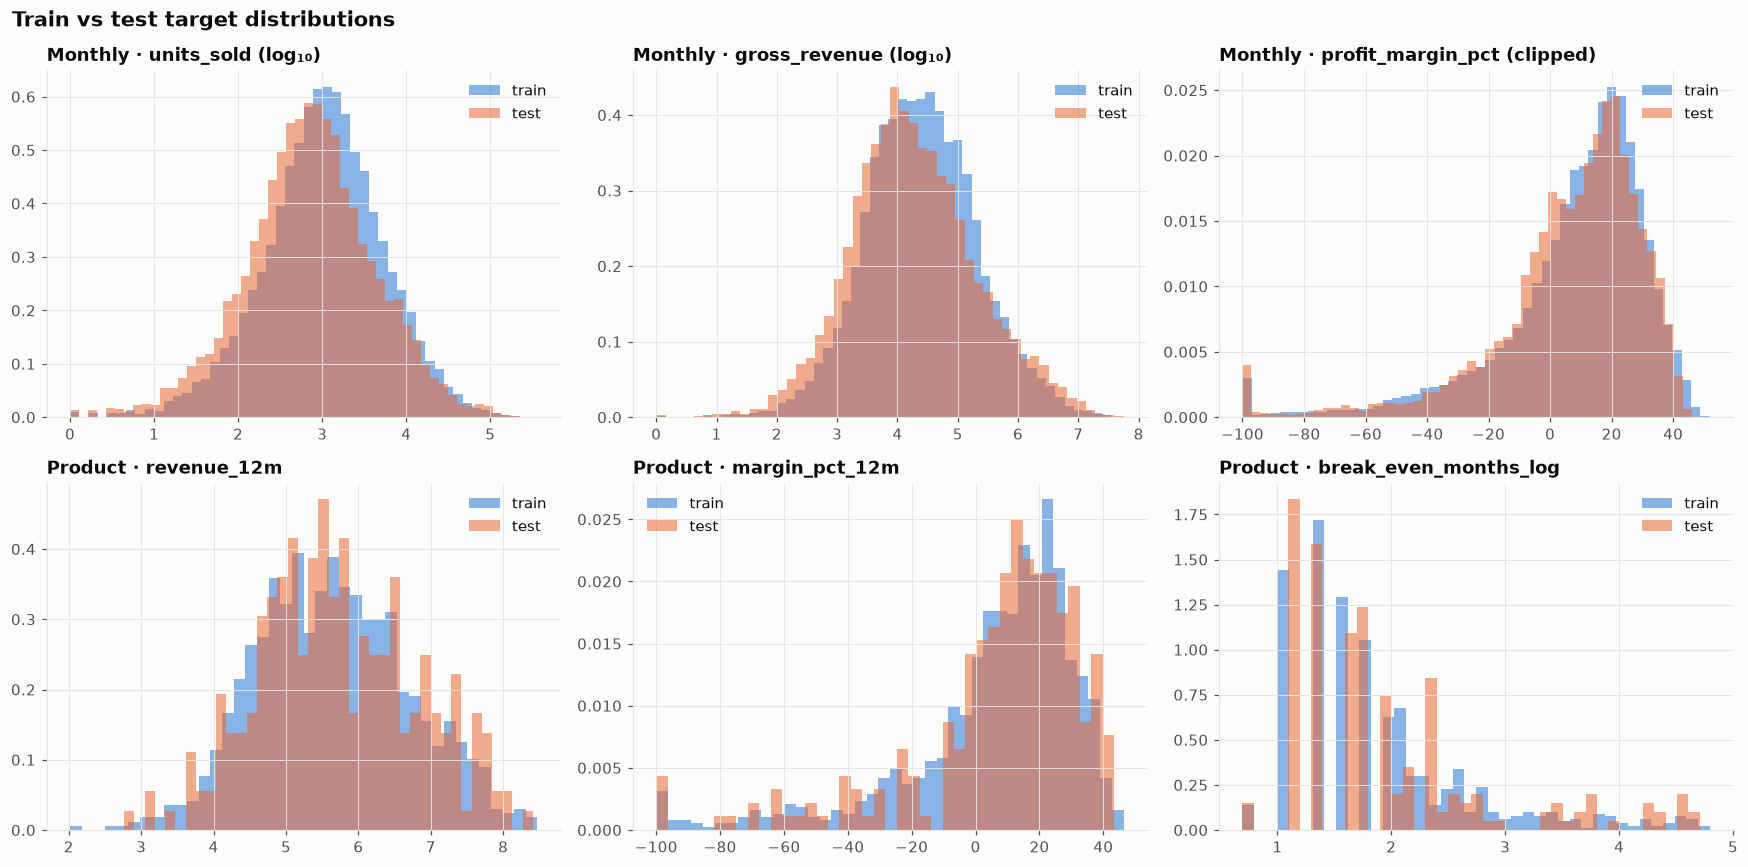

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes[0], ["units_sold", "gross_revenue", "profit_margin_pct"]):
    tr = np.log10(m_train[col].clip(lower=1)) if col != "profit_margin_pct" else m_train[col].clip(-100, 60)
    te = np.log10(m_test[col].clip(lower=1)) if col != "profit_margin_pct" else m_test[col].clip(-100, 60)
    ax.hist(tr, bins=50, density=True, color=SERIES[0], alpha=.55, label="train")
    ax.hist(te, bins=50, density=True, color=SERIES[1], alpha=.55, label="test")
    ax.set(title=f"Monthly · {col}" + (" (log₁₀)" if col != "profit_margin_pct" else " (clipped)")); ax.legend()
for ax, col in zip(axes[1], ["revenue_12m", "margin_pct_12m", "break_even_months_log"]):
    a, b = p_train[col].dropna(), p_test[col].dropna()
    if col == "revenue_12m": a, b = np.log10(a.clip(lower=1)), np.log10(b.clip(lower=1))
    if col == "margin_pct_12m": a, b = a.clip(-100, 60), b.clip(-100, 60)
    ax.hist(a, bins=40, density=True, color=SERIES[0], alpha=.55, label="train")
    ax.hist(b, bins=40, density=True, color=SERIES[1], alpha=.55, label="test")
    ax.set(title=f"Product · {col}"); ax.legend()
fig.suptitle("Train vs test target distributions", x=.01, ha="left", fontweight="bold", fontsize=14)
fig.tight_layout(); savefig(fig, "04_split_distributions")

col_0,train,test,test_share
category_group,,,
Camera & Photo,13,3,0.19
Cell Phones & Accessories,170,43,0.20
Computer Accessories & Peripherals,254,64,0.20
Computers & Accessories,45,12,0.21
Electronics - Accessories,21,5,0.19
Electronics - Audio,63,16,0.20
Electronics - TV & Video,125,31,0.20
Home & Kitchen,19,5,0.21
Kitchen & Home Appliances,339,85,0.20


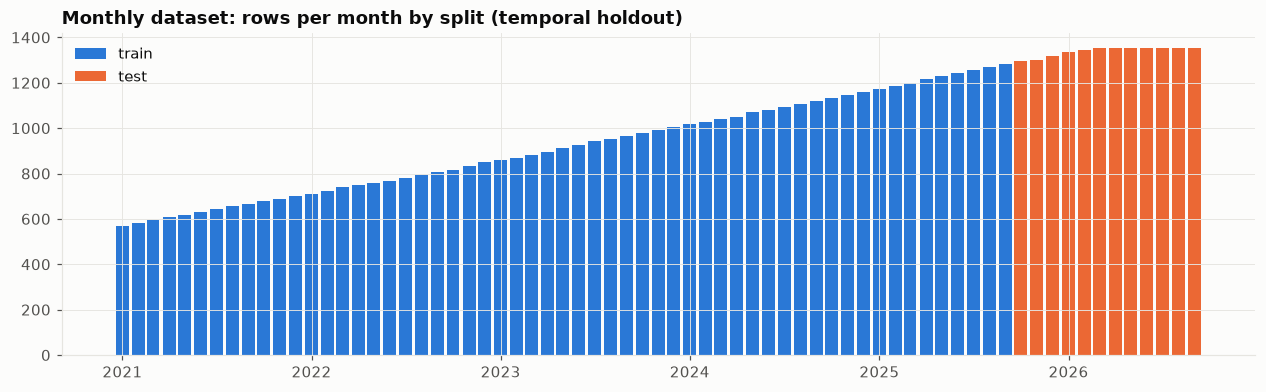

In [9]:
fig, ax = plt.subplots(figsize=(14, 3.8))
cnt = pd.concat([m_train.assign(split="train"), m_test.assign(split="test")]).groupby(["month", "split"]).size().unstack()
ax.bar(cnt.index, cnt["train"].fillna(0), width=25, color=SERIES[0], label="train")
ax.bar(cnt.index, cnt["test"].fillna(0), width=25, color=SERIES[1], label="test")
ax.set(title="Monthly dataset: rows per month by split (temporal holdout)"); ax.legend(loc="upper left"); fmt_dates(ax)
savefig(fig, "04_temporal_split")
pd.crosstab(p_train.category_group, "train").join(pd.crosstab(p_test.category_group, "test")).assign(
    test_share=lambda d: (d.test / (d.train + d.test)).round(2))

## 6. Save final datasets, feature spec and data dictionary

In [10]:
outputs = {"monthly_train": m_train, "monthly_test": m_test, "yearly_train": y_train, "yearly_test": y_test,
           "yearly_2026_partial": y_score, "product_train": p_train, "product_test": p_test}
for name, d in outputs.items():
    d.to_csv(FINAL / f"{name}.csv", index=False)
    print(f"{name:22s} {d.shape[0]:>7,} rows × {d.shape[1]:>3} cols")

spec = {
    "monthly": {"features": MONTHLY_FEATURES, "targets": MONTHLY_TARGETS, "drop_when_target_is_price": PRICE_INPUTS,
                "split": f"temporal: train < {SPLIT:%Y-%m}, test >= {SPLIT:%Y-%m}", "id_cols": ["product_id", "month"]},
    "yearly": {"features": YEARLY_FEATURES, "targets": YEARLY_TARGETS, "split": "temporal: train <= 2024, test = 2025, 2026 partial"},
    "product": {"launch_features": LAUNCH_FEATURES, "listing_features": LISTING_FEATURES, "targets": LAUNCH_TARGETS,
                "split": "80/20 product-level, stratified by category_group, random_state=42"},
    "categorical_raw_cols_for_pipeline_encoding": ["brand", "cat_leaf"],
    "log_targets_recommended": ["units_sold", "demand_units", "gross_revenue", "units_sold_12m", "revenue_12m", "break_even_months"],
    "notes": "Financial values are simulated approximations for the U.S. market; see notebook 03 and data/reference/.",
}
(FINAL / "feature_spec.json").write_text(json.dumps(spec, indent=2, default=str))
print("feature_spec.json written")

monthly_train           52,245 rows × 127 cols


monthly_test            16,054 rows × 127 cols
yearly_train             5,244 rows ×  80 cols
yearly_test              1,320 rows ×  80 cols
yearly_2026_partial      1,351 rows ×  80 cols
product_train            1,080 rows ×  79 cols
product_test               271 rows ×  79 cols
feature_spec.json written


In [11]:
DESC = {
    "units_sold": "Units shipped to customers in the period", "demand_units": "Unconstrained customer demand (units sold + lost to stock-outs)",
    "demand_share_pct": "Product demand ÷ total tracked demand in its U.S. category × 100", "demand_growth_mom_pct": "Month-over-month % change in demand",
    "demand_growth_yoy_pct": "Year-over-year % change in demand", "avg_price": "Average selling price after promotions (USD)",
    "gross_revenue": "Units × selling price before returns (USD)", "net_profit": "Net revenue − referral, FBA, storage, COGS, ads, overhead (USD)",
    "profit_margin_pct": "Net profit ÷ gross revenue × 100", "roi_unit_pct": "Profit per unit ÷ landed cost per unit × 100",
    "roi_cum_pct": "Cumulative net profit since launch ÷ capital invested × 100", "roi_year_pct": "Net profit in year ÷ capital invested × 100",
    "break_even_months": "Months from launch until cumulative cash ≥ capital invested (payback)", "never_breaks_even": "1 if payback not reached within 10 years",
    "break_even_bucket": "Payback class: 0-3m, 4-6m, 7-12m, 13-24m, 24m+, never",
    "log_price_usd": "ln(1 + everyday sale price in USD)", "discount_pct": "Everyday discount vs U.S. reference price (%)",
    "rating": "Average star rating", "listing_quality_score": "0–100 composite of content richness, rating and sentiment",
    "fba_fee_unit": "Estimated 2025 U.S. FBA fulfilment fee per unit", "landed_cost_unit": "Manufacturing + freight + duties per unit",
    "unit_margin_pct": "Pre-ad unit contribution margin at everyday price", "price_elasticity": "Category own-price elasticity used for promo months",
    "macro_index": "U.S. e-commerce macro demand index (Jan 2021 = 1)", "promo_depth_pct": "Promotional discount depth in the month (%)",
    "price_vs_everyday": "Selling price ÷ everyday price", "is_prime_day": "Month contains Prime Day", "is_bfcm": "November (Black Friday / Cyber Monday)",
    "reviews_to_date_lag1": "Ratings accumulated up to the previous month", "log_rating_count": "ln(1 + total ratings), listing-evaluation use only",
}
rows = []
for ds, d in [("monthly", m_train), ("yearly", y_train), ("product", p_train)]:
    tg = set(spec[ds]["targets"]) if ds != "product" else set(LAUNCH_TARGETS)
    for c in d.columns:
        base = re.sub(r"_(lag\d+|roll\d+_mean|prev_year)$", "", c)
        desc = DESC.get(c) or (DESC.get(base, base.replace("_", " ")) + (f" ({c.split(base + '_')[-1].replace('_', ' ')})" if base != c else ""))
        if "__" in c: desc = f"One-hot: {c.split('__')[0]} = {c.split('__')[1]}"
        rows.append({"dataset": ds, "column": c, "role": "target" if c in tg else ("id" if c in ID_COLS + ["month", "product_id", "launch_date"] else "feature"),
                     "dtype": str(d[c].dtype), "null_pct": round(d[c].isna().mean() * 100, 2), "description": desc})
dd = pd.DataFrame(rows); dd.to_csv(FINAL / "data_dictionary.csv", index=False)
dd[dd.role == "target"]

,dataset,column,role,dtype,null_pct,description
23,monthly,avg_price,target,float64,0.00,Average selling price after promotions (USD)
117,monthly,units_sold,target,int64,0.00,Units shipped to customers in the period
118,monthly,demand_units,target,int64,0.00,Unconstrained customer demand (units sold + lo...
119,monthly,demand_share_pct,target,float64,0.00,Product demand ÷ total tracked demand in its U...
120,monthly,demand_growth_mom_pct,target,float64,1.40,Month-over-month % change in demand
121,monthly,gross_revenue,target,float64,0.00,Units × selling price before returns (USD)
122,monthly,net_profit,target,float64,0.00,"Net revenue − referral, FBA, storage, COGS, ad..."
123,monthly,profit_margin_pct,target,float64,0.02,Net profit ÷ gross revenue × 100
124,monthly,roi_unit_pct,target,float64,0.02,Profit per unit ÷ landed cost per unit × 100
125,monthly,roi_cum_pct,target,float64,0.00,Cumulative net profit since launch ÷ capital i...


## Summary
**`data/final/`** is ready for modelling:

| File | Rows | Purpose |
|---|---|---|
| `monthly_train.csv` / `monthly_test.csv` | ~52k / ~13k | Next-month forecasts: units, demand (units, %), price, revenue, profit, margin, ROI |
| `yearly_train.csv` / `yearly_test.csv` (+ `yearly_2026_partial.csv`) | product-years | Annual forecasts and YoY demand growth |
| `product_train.csv` / `product_test.csv` | 1,080 / 271 | Launch and investment evaluation: first 12/24-month metrics, **break-even months** |
| `feature_spec.json` | | Feature and target lists per dataset, leakage notes, split rules |
| `data_dictionary.csv` | | Every column with role, dtype, null %, description |

**Recommended next steps (modelling notebooks → backend code)**
1. Baselines: seasonal naive (same month last year) for monthly; category medians for launch metrics.
2. Gradient-boosted trees (LightGBM / XGBoost) on log targets. Quantile objectives give P10/P50/P90 ranges for investor-facing uncertainty.
3. Break-even: regression on `break_even_months_log` + classifier on `break_even_bucket` / `never_breaks_even`.
4. Fit target encoding for `brand` / `cat_leaf` inside the pipeline (on train only).
5. Package the cleaning → feature → simulation logic from notebooks 01–03 into `src/` modules with the assumption tables as config.